<a href="https://colab.research.google.com/github/andresjaimes2004/tesis-desercion/blob/main/notebooks/04_evaluacion_shap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 · Evaluación y explicabilidad (OE3)

Fase 5 de CRISP-DM. Optimiza los hiperparámetros de los cuatro modelos que pasaron la Fase 4, selecciona el modelo final, fija el umbral de decisión con el entrenamiento y evalúa **una sola vez** en el conjunto de prueba. Al final explica las predicciones con valores SHAP.

**Tiempo estimado en Colab: entre 10 y 25 minutos.** No cierres la pestaña mientras corre.

In [1]:
# Preparar el entorno (igual que en el cuaderno 00)
import os, sys
REPO_URL = "https://github.com/andresjaimes2004/tesis-desercion.git"
REPO_DIR = "/content/tesis-desercion"
if "google.colab" in sys.modules and not os.path.exists(REPO_DIR):
    !git clone -q {REPO_URL} {REPO_DIR}
if os.path.exists(REPO_DIR):
    os.chdir(REPO_DIR)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
%pip install -q -r requirements.txt

In [2]:
import os, warnings
os.environ["PYTHONWARNINGS"] = "ignore:Unknown solver options"  # también en los procesos paralelos
warnings.filterwarnings("ignore", message="Unknown solver options")  # aviso interno de SciPy, no afecta resultados

import pandas as pd
from src import config, plots, prep, evaluation as ev, explain
from src.data import load_raw, binarize_target
from src.utils import set_seed

set_seed()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 250)
df = prep.add_no_enrollment_flags(binarize_target(load_raw()))
idx_train, idx_test = prep.load_split()
y_test = df.loc[idx_test, config.BINARY_TARGET]
print("Entrenamiento:", len(idx_train), "| Prueba:", len(idx_test))

Entrenamiento: 3539 | Prueba: 885


## 1. Optimización de hiperparámetros

Búsqueda en malla para la regresión logística y búsqueda aleatoria para Random Forest, XGBoost y SVM, con AUC-ROC en validación cruzada estratificada de 5 pliegues sobre el entrenamiento. La ponderación de clases entra como un hiperparámetro más (con o sin ponderación). Momento: cierre del 2.º semestre.

In [3]:
optimizacion, mejores = ev.tune(df, idx_train)
optimizacion.to_csv(config.REPORTS / "optimizacion.csv", index=False, encoding="utf-8-sig")
optimizacion[["modelo", "auc_cv", "auc_de", "auc_ee", "combinaciones", "variables"]].round(4)

Regresión logística AUC CV = 0.9172 ± 0.0086 | {'C': 0.31622776601683794, 'class_weight': None}
Random Forest       AUC CV = 0.9160 ± 0.0061 | {'n_estimators': 300, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 15, 'class_weight': 'balanced'}
XGBoost             AUC CV = 0.9206 ± 0.0048 | {'colsample_bytree': 0.6955303037866204, 'learning_rate': 0.018585951462501547, 'max_depth': 5, 'min_child_weight': 2, 'n_estimators': 489, 'reg_lambda': 0.26054534945804003, 'scale_pos_weight': 2.1125769569041335, 'subsample': 0.6739417822102108}
SVM                 AUC CV = 0.9176 ± 0.0054 | {'C': 9.717775305059629, 'class_weight': 'balanced', 'gamma': 0.0018856783874794994}


,modelo,auc_cv,auc_de,auc_ee,combinaciones,variables
0,XGBoost,0.9206,0.0048,0.0022,40,31
1,SVM,0.9176,0.0054,0.0024,20,31
2,Regresión logística,0.9172,0.0086,0.0039,22,31
3,Random Forest,0.9160,0.0061,0.0027,30,31


## 2. Selección del modelo final

Gana el mayor AUC-ROC. Criterio de parsimonia fijado de antemano: si la regresión logística queda a menos de un error estándar del mejor, se elige la regresión logística por ser la más simple e interpretable.

In [4]:
modelo_final = ev.select(optimizacion)
parametros = mejores[modelo_final]
print("Modelo final:", modelo_final)
print("Hiperparámetros:", parametros)

Modelo final: XGBoost
Hiperparámetros: {'colsample_bytree': 0.6955303037866204, 'learning_rate': 0.018585951462501547, 'max_depth': 5, 'min_child_weight': 2, 'n_estimators': 489, 'reg_lambda': 0.26054534945804003, 'scale_pos_weight': 2.1125769569041335, 'subsample': 0.6739417822102108}


## 3. Umbral de decisión y evaluación en los tres momentos

Para cada momento: el umbral se elige con probabilidades fuera de pliegue **del entrenamiento** (el más alto que mantiene una sensibilidad de al menos 0,80), luego el modelo se entrena con todo el entrenamiento y se evalúa una única vez en la prueba.

In [5]:
momentos, salidas = ev.evaluate_moments(df, idx_train, idx_test, modelo_final, parametros)
momentos.to_csv(config.REPORTS / "evaluacion_momentos.csv", index=False, encoding="utf-8-sig")
especificacion = ev.save_final(modelo_final, parametros, salidas)
momentos.round(3)

,momento,variables,umbral,exactitud,sensibilidad,precision,f1,auc_roc,brier,vp,fp,fn,vn
0,matricula,19,0.352,0.682,0.827,0.503,0.626,0.839,0.155,235,232,49,369
1,semestre_1,31,0.419,0.838,0.824,0.716,0.766,0.916,0.104,234,93,50,508
2,semestre_2,31,0.440,0.873,0.845,0.779,0.811,0.935,0.090,240,68,44,533


## 4. Evaluación detallada al cierre del 2.º semestre

Métricas con el umbral elegido y con el umbral convencional de 0,5, intervalos de confianza del 95 % por bootstrap (1.000 remuestreos de la prueba) y verificación de los criterios de éxito.

,umbral,exactitud,sensibilidad,precision,f1,auc_roc,brier,vp,fp,fn,vn
umbral elegido,0.44,0.873,0.845,0.779,0.811,0.935,0.09,240,68,44,533
"umbral 0,5",0.50,0.878,0.824,0.801,0.812,0.935,0.09,234,58,50,543


,ic95_inferior,ic95_superior
sensibilidad,0.799,0.885
precision,0.727,0.822
f1,0.772,0.842
auc_roc,0.916,0.952
brier,0.079,0.104


,criterio,valor,cumple
0,"Sensibilidad ≥ 0,80",0.845070,True
1,"Precisión ≥ 0,70",0.779221,True
2,"Brier < 0,218",0.090410,True


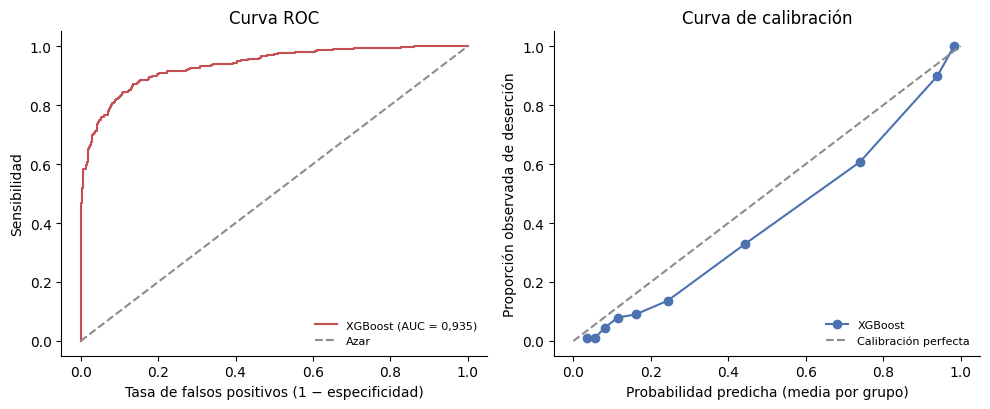

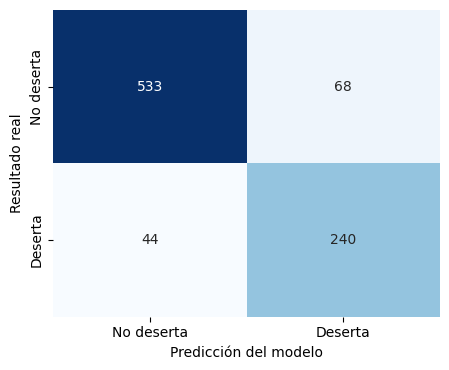

In [6]:
s2 = salidas["semestre_2"]
p_test, umbral = s2["p_test"], s2["umbral"]
evaluacion = pd.DataFrame([ev.metrics(y_test, p_test, umbral), ev.metrics(y_test, p_test, 0.5)],
                          index=["umbral elegido", "umbral 0,5"])
evaluacion.to_csv(config.REPORTS / "evaluacion_prueba.csv", encoding="utf-8-sig")
ic = pd.DataFrame(ev.bootstrap_ci(y_test, p_test, umbral), index=["ic95_inferior", "ic95_superior"]).T
ic.to_csv(config.REPORTS / "intervalos_confianza.csv", encoding="utf-8-sig")
criterios = ev.success_table(evaluacion.loc["umbral elegido"])
criterios.to_csv(config.REPORTS / "criterios_exito.csv", index=False, encoding="utf-8-sig")
plots.roc_calibration(y_test, p_test, modelo_final)
plots.confusion(evaluacion.loc["umbral elegido"])
display(evaluacion.round(3)); display(ic.round(3)); criterios

## 5. Explicabilidad con valores SHAP

Se explican las predicciones del modelo final sobre el conjunto de prueba. La importancia global suma los aportes de las columnas one-hot de cada variable original. Se compara con el tamaño del efecto de la Fase 2 (correlación de Spearman) para verificar coherencia.

Coherencia con la Fase 2: rho de Spearman = 0.834 sobre 29 variables
deserción detectada | índice 3533 | riesgo 0.996
deserción no detectada | índice 3003 | riesgo 0.045


,variable,etiqueta,importancia_shap
0,Curricular units 2nd sem (approved),"Unidades aprobadas, 2.º sem.",1.0966
1,Tuition fees up to date,Matrícula al día,0.4038
2,Curricular units 1st sem (approved),"Unidades aprobadas, 1.er sem.",0.3527
3,Age at enrollment,Edad al ingresar,0.2908
4,Curricular units 2nd sem (grade),"Nota promedio, 2.º sem.",0.2618
5,Course,Programa académico,0.1927
6,Curricular units 2nd sem (enrolled),"Unidades inscritas, 2.º sem.",0.1511
7,Scholarship holder,Becario,0.1341
8,Gender,Género,0.1088
9,Debtor,Deudor,0.1064


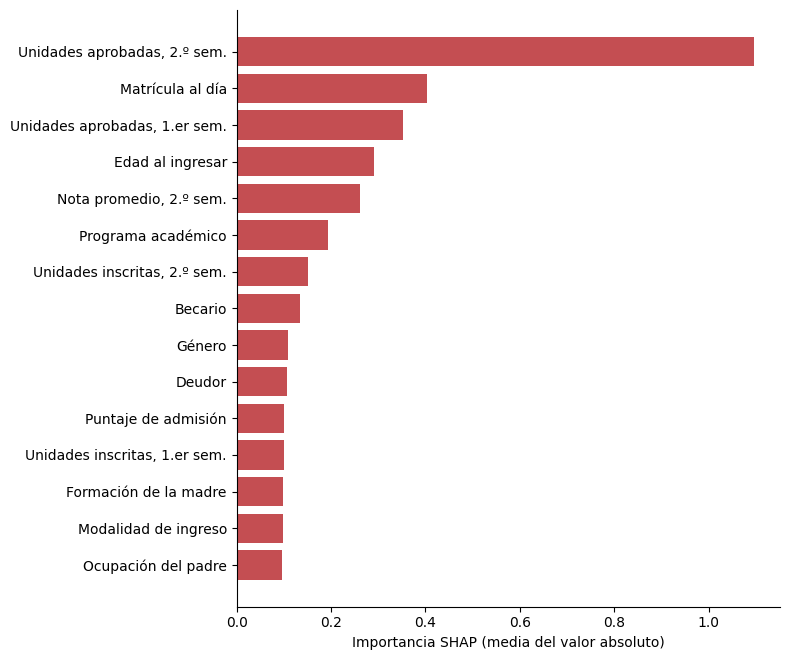

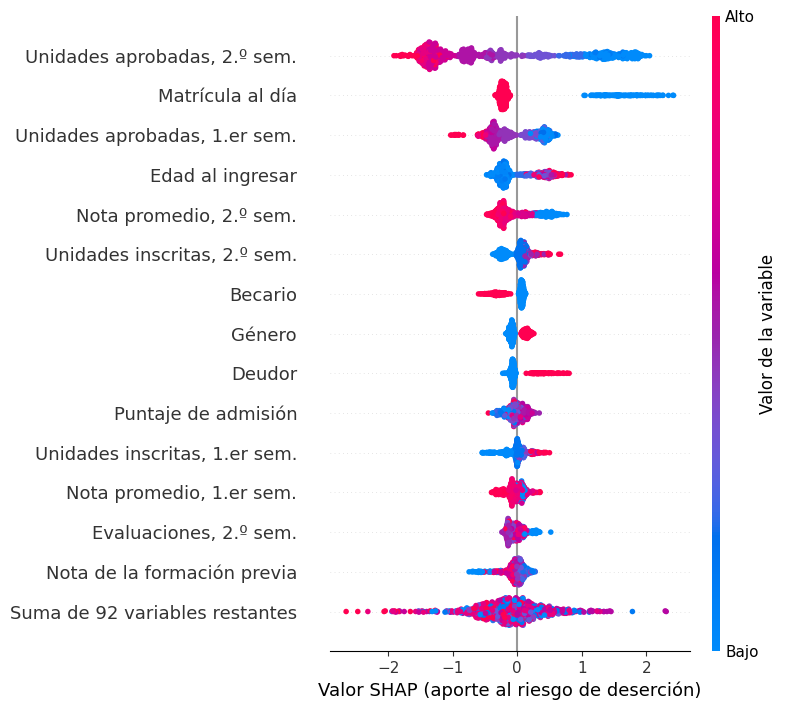

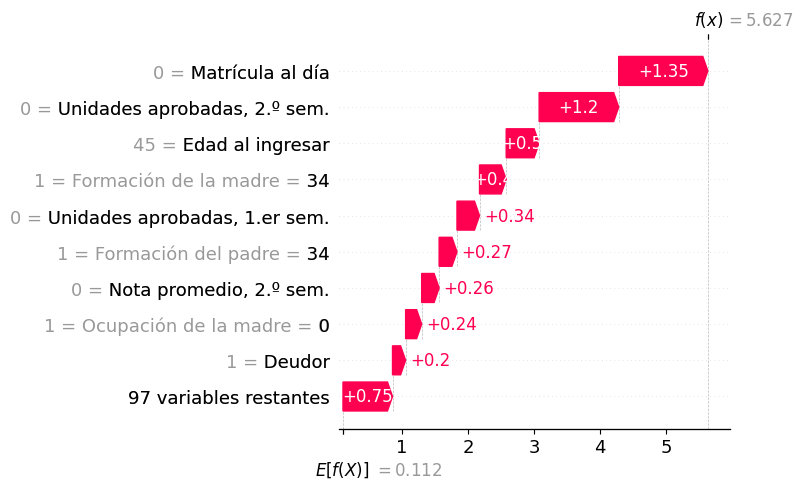

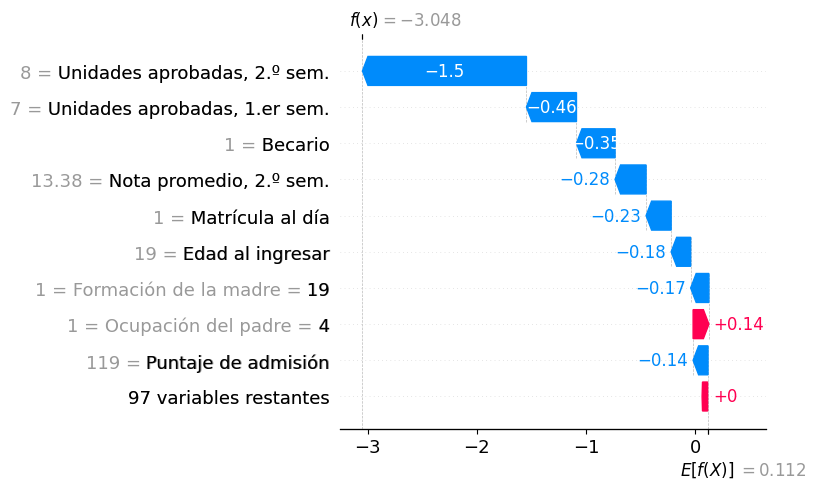

In [7]:
pipe, cols = s2["pipeline"], s2["cols"]
X_test = df.loc[idx_test, cols]
casos = explain.pick_cases(y_test, p_test, umbral)
filas = X_test.index
if modelo_final == "SVM":   # el explicador por permutaciones es lento: muestra de 200 + los casos
    filas = X_test.sample(200, random_state=config.SEED).index.union(pd.Index(list(casos.values())))
exp, Xt = explain.shap_values(pipe, df.loc[idx_train, cols], X_test.loc[filas])
omap = explain.origin_map(df, cols, exp.feature_names)
etiquetas = [explain.readable(f, omap[f]) for f in exp.feature_names]

importancia = explain.global_importance(exp, df, cols)
importancia.to_csv(config.REPORTS / "shap_importancia.csv", index=False, encoding="utf-8-sig")
rho, n_var = explain.coherence_with_oe1(importancia)
print(f"Coherencia con la Fase 2: rho de Spearman = {rho:.3f} sobre {n_var} variables")

plots.shap_global(importancia)
plots.shap_beeswarm(exp, etiquetas)
pos = {idx: i for i, idx in enumerate(Xt.index)}
for nombre, idx in casos.items():
    archivo = "fig_12_shap_caso_detectado" if "no" not in nombre else "fig_13_shap_caso_no_detectado"
    print(nombre, "| índice", idx, "| riesgo", round(float(pd.Series(p_test, index=y_test.index)[idx]), 3))
    plots.shap_case(exp[pos[idx]], etiquetas, archivo,
                    raw_values=explain.raw_row(X_test.loc[idx], exp.feature_names, omap))
importancia.head(15).round(4)

## 6. Resumen para el documento

Ejecutar esta celda y enviar su salida completa.

In [8]:
print("OPTIMIZACIÓN (AUC-ROC en validación cruzada, 2.º semestre):")
print(optimizacion.round(4).to_string(index=False))
print("\nMODELO FINAL:", modelo_final, "|", parametros)
print("\nEVALUACIÓN EN PRUEBA POR MOMENTO:")
print(momentos.round(3).to_string(index=False))
print("\nEVALUACIÓN DETALLADA 2.º SEMESTRE:")
print(evaluacion.round(3).to_string())
print("\nINTERVALOS DE CONFIANZA 95 % (bootstrap):")
print(ic.round(3).to_string())
print("\nCRITERIOS DE ÉXITO:")
print(criterios.round(3).to_string(index=False))
print(f"\nSHAP: coherencia con la Fase 2, rho = {rho:.3f} ({n_var} variables)")
print(importancia.head(15).round(4).to_string(index=False))
for nombre, idx in casos.items():
    i = pos[idx]
    top = pd.Series(exp.values[i], index=etiquetas).sort_values(key=abs, ascending=False).head(5)
    print(f"\nCASO {nombre.upper()} (riesgo {pd.Series(p_test, index=y_test.index)[idx]:.3f}):")
    print(top.round(3).to_string())

OPTIMIZACIÓN (AUC-ROC en validación cruzada, 2.º semestre):
             modelo  auc_cv  auc_de  auc_ee  combinaciones  variables                                                                                                                                                                                                                                      mejores_parametros
            XGBoost  0.9206  0.0048  0.0022             40         31 {"colsample_bytree": 0.6955303037866204, "learning_rate": 0.018585951462501547, "max_depth": 5, "min_child_weight": 2, "n_estimators": 489, "reg_lambda": 0.26054534945804003, "scale_pos_weight": 2.1125769569041335, "subsample": 0.6739417822102108}
                SVM  0.9176  0.0054  0.0024             20         31                                                                                                                                                                    {"C": 9.717775305059629, "class_weight": "balanced", "gamma": 0.0018856

## 7. Guardar resultados en GitHub

La siguiente celda empaqueta la carpeta `reports/` en `reports_fase5.zip`. Descárgalo, descomprímelo y sube su contenido a la carpeta `reports` del repositorio con el mensaje `Fase 5: evaluación y SHAP`. Luego guarda este cuaderno con Archivo > Guardar una copia en GitHub.

In [10]:
!cd /content/tesis-desercion && zip -qr /content/reports_fase5.zip reports && echo "Listo: /content/reports_fase5.zip"

Listo: /content/reports_fase5.zip


In [11]:
# Criterio 4: AUC-ROC del modelo final frente a la regresión logística de referencia (prueba)
import json
from sklearn.metrics import roc_auc_score
opt = pd.read_csv(config.REPORTS / "optimizacion.csv")
tr, te = df.loc[idx_train], df.loc[idx_test]
filas = []
for _, r in opt.iterrows():
    cols_m = ev.columns(df, r["modelo"], "semestre_2")
    pipe_m = ev.final_pipeline(df, cols_m, r["modelo"], json.loads(r["mejores_parametros"]))
    pipe_m.fit(tr[cols_m], tr[config.BINARY_TARGET])
    p_m = pipe_m.predict_proba(te[cols_m])[:, 1]
    filas.append({"modelo": r["modelo"], "auc_cv": r["auc_cv"], "auc_prueba": roc_auc_score(y_test, p_m)})
referencia = pd.DataFrame(filas)
referencia.to_csv(config.REPORTS / "auc_prueba_modelos.csv", index=False, encoding="utf-8-sig")
print(referencia.round(4).to_string(index=False))

             modelo  auc_cv  auc_prueba
            XGBoost  0.9206      0.9354
                SVM  0.9176      0.9299
Regresión logística  0.9172      0.9266
      Random Forest  0.9160      0.9291
